# artifacts: примеры объектов

Сначала посмотрим, как выглядят объекты с меткой `artifacts` и чем они отличаются от `noisy`.

Сохранённые выводы относятся к предыдущим запускам. После рефакторинга полное обучение не повторялось.

Порядок запуска: сверху вниз, в отдельном kernel. Данные и локальные модели нужны отдельно от Git. Установка и список файлов — в [инструкции](../../docs/RUNNING.md).

## Данные

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data/train.csv').exists()), None)
if ROOT is None:
    ROOT = Path('/content/drive/MyDrive/Colab Notebooks/colab_upload/AI challenge main')
import sys
sys.path.insert(0, str(ROOT))
from src.evaluation import binary_metrics, best_threshold
from src.data import split_indices, load_embeddings
from src.plots import setup_plot_style
setup_plot_style()
assert (ROOT / 'data/train.csv').exists(), ROOT
train = pd.read_csv(ROOT / 'data/train.csv')
print('artifacts:', train['artifacts'].sum())
print('artifacts + noisy:', ((train['artifacts'] == 1) & (train['noisy'] == 1)).sum())

artifacts: 435
artifacts + noisy: 172


## Пять примеров artifacts

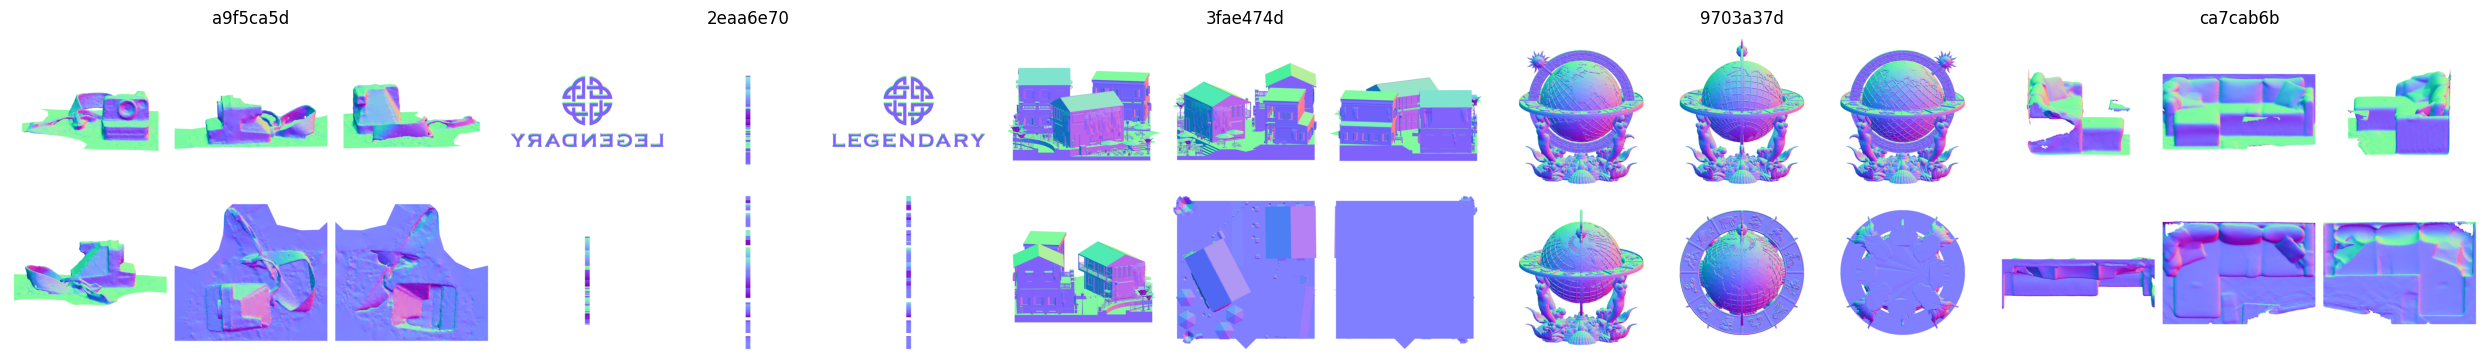

,item_id,artifacts,noisy,lowpoly
6005,a9f5ca5d-3b30-4bea-988c-ea625cc9f22c,1,1,0
1658,2eaa6e70-077b-40f5-aa16-67b674eb709d,1,0,0
2284,3fae474d-27cd-4114-bbb9-55892b4ce29b,1,1,0
5284,9703a37d-8140-40db-a648-a47c59db8238,1,1,1
7089,ca7cab6b-333b-4721-9da2-34303b0b0b56,1,1,0


In [2]:
def show_examples(rows):
    fig, axes = plt.subplots(1, len(rows), figsize=(25, 4))
    for ax, item_id in zip(axes, rows['item_id']):
        with Image.open(ROOT / 'data/train' / f'{item_id}.png') as image:
            ax.imshow(image)
        ax.set_title(item_id[:8])
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    display(rows[['item_id', 'artifacts', 'noisy', 'lowpoly']])

examples = train[train['artifacts'] == 1].sample(5, random_state=42)
show_examples(examples)

## Для сравнения: noisy без artifacts

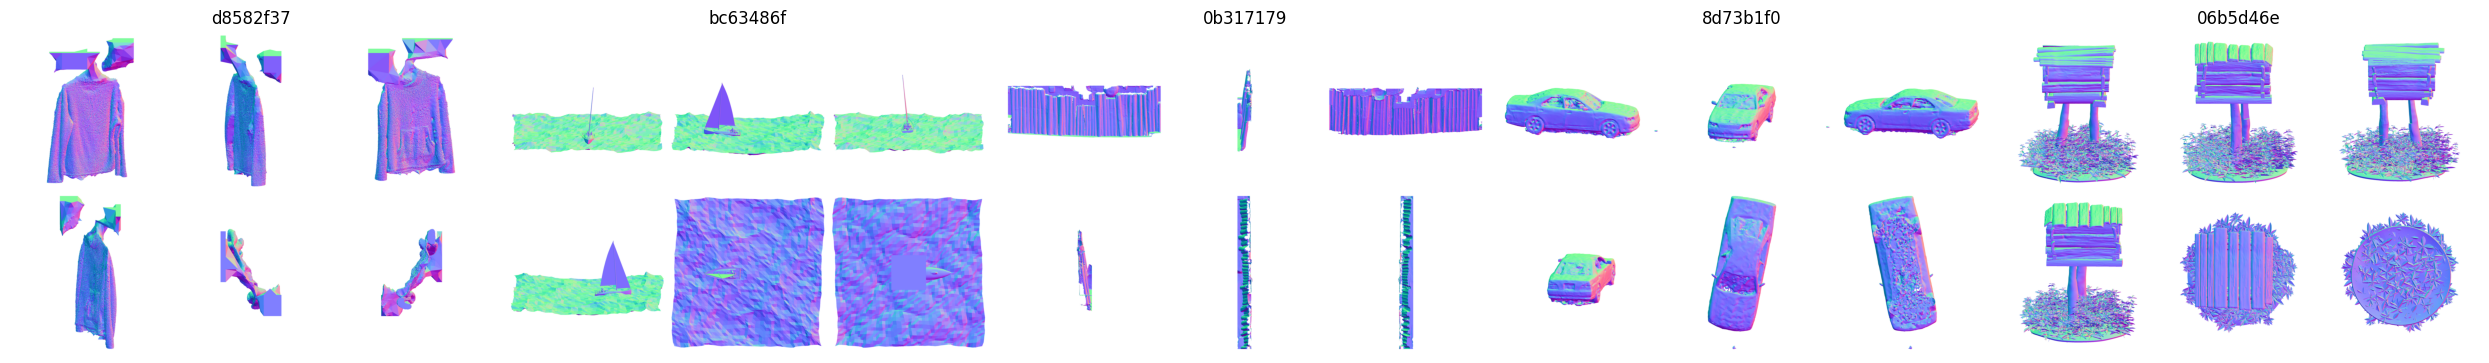

,item_id,artifacts,noisy,lowpoly
7572,d8582f37-c617-4ac7-9801-878ea568a5a4,0,1,0
6607,bc63486f-0af9-407f-bc4c-a2623b2bea08,0,1,0
373,0b317179-ca07-4259-9476-e291267da6bf,0,1,0
4950,8d73b1f0-be16-4ff1-939b-85833c1df90d,0,1,0
226,06b5d46e-4dac-4629-8afe-b61c1023825a,0,1,0


In [3]:
examples = train[(train['noisy'] == 1) & (train['artifacts'] == 0)].sample(5, random_state=42)
show_examples(examples)

## Как читать результат

F1 сравниваем на том же split. Порог и вариант модели выбираем по validation; internal test для подбора не используем. Повторный выбор по одной validation может завысить оценку. История и ограничения сохранены в [журнале](../../docs/experiments/artifacts.md). Формулы признаков — в [методике](../../docs/METHODS.md).